## Download and Import Dataset


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('Automobile.csv')
df.head()

,name,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,70,usa
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,70,usa
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,70,usa
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,70,usa
4,ford torino,17.0,8,302.0,140.0,3449,10.5,70,usa


## Data Cleaning and preprocessing 

In [3]:
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          398 non-null    object 
 1   mpg           398 non-null    float64
 2   cylinders     398 non-null    int64  
 3   displacement  398 non-null    float64
 4   horsepower    392 non-null    float64
 5   weight        398 non-null    int64  
 6   acceleration  398 non-null    float64
 7   model_year    398 non-null    int64  
 8   origin        398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


0

In [4]:
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

In [5]:
df.isnull().sum()   

name            0
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

In [6]:
df = pd.get_dummies(df, columns=['origin'], drop_first=True)

In [7]:
df.head()
df.columns.tolist()

['name',
 'mpg',
 'cylinders',
 'displacement',
 'horsepower',
 'weight',
 'acceleration',
 'model_year',
 'origin_japan',
 'origin_usa']

In [8]:
from sklearn.preprocessing import StandardScaler

num_cols = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])

In [9]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   name          398 non-null    object 
 1   mpg           398 non-null    float64
 2   cylinders     398 non-null    float64
 3   displacement  398 non-null    float64
 4   horsepower    398 non-null    float64
 5   weight        398 non-null    float64
 6   acceleration  398 non-null    float64
 7   model_year    398 non-null    float64
 8   origin_japan  398 non-null    bool   
 9   origin_usa    398 non-null    bool   
dtypes: bool(2), float64(7), object(1)
memory usage: 25.8+ KB


In [10]:
df_raw = pd.read_csv('Automobile.csv')
df_raw['horsepower'] = df_raw['horsepower'].fillna(df_raw['horsepower'].median())

## Data Visualization

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

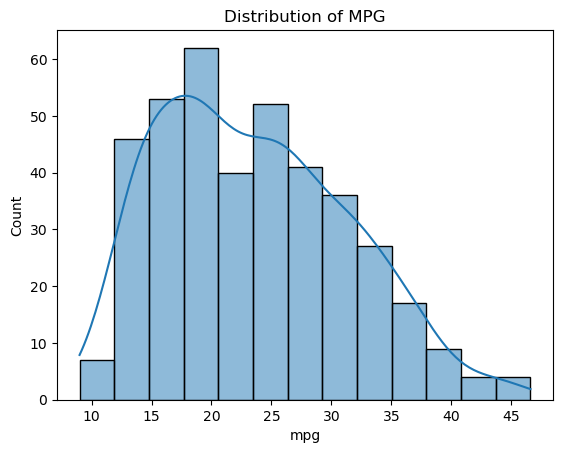

In [12]:
sns.histplot(df_raw['mpg'], kde=True)
plt.title('Distribution of MPG')
plt.show()

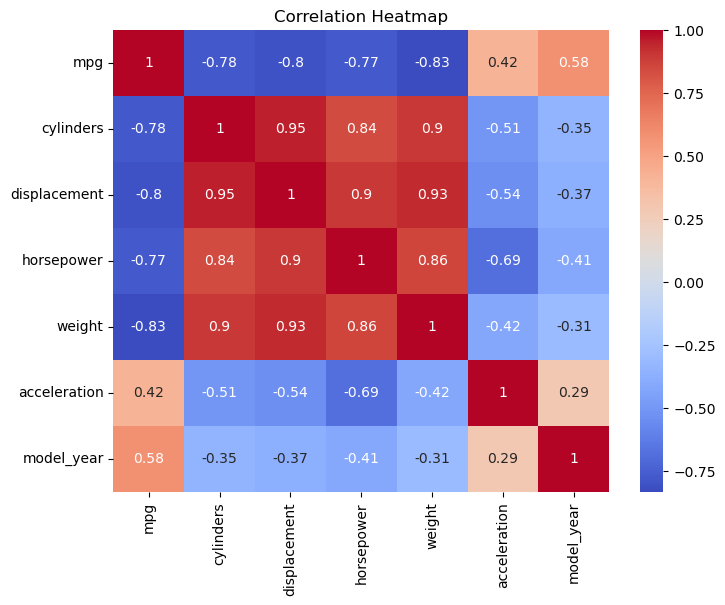

In [13]:
plt.figure(figsize=(8,6))
sns.heatmap(df_raw.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [15]:
df_raw['mpg'].skew()

0.45706634399491913

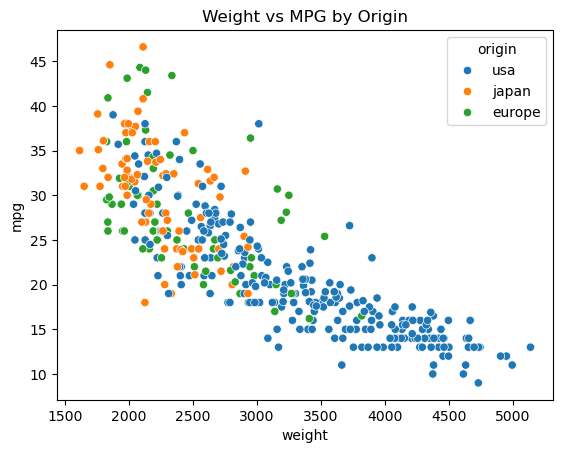

In [16]:
sns.scatterplot(x='weight', y='mpg', data=df_raw, hue='origin')
plt.title('Weight vs MPG by Origin')
plt.show()

C:\Users\KhanJ\AppData\Local\Temp\ipykernel_3436\1226373712.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x='model_year', y='mpg', data=df_raw, ci=None)


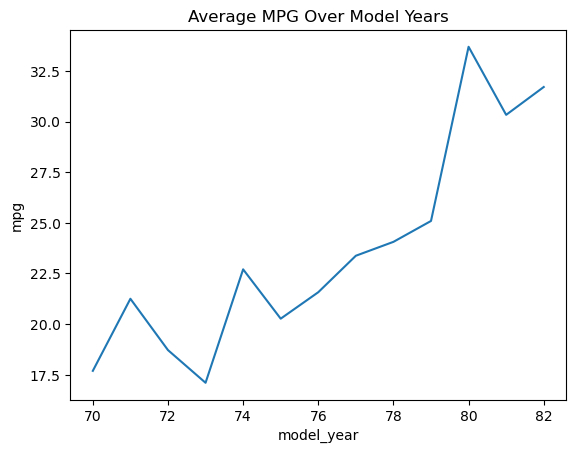

In [17]:
sns.lineplot(x='model_year', y='mpg', data=df_raw, ci=None)
plt.title('Average MPG Over Model Years')
plt.show()

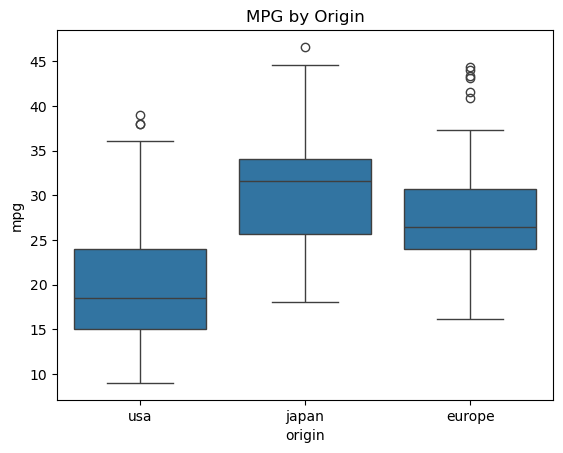

In [18]:
sns.boxplot(x='origin', y='mpg', data=df_raw)
plt.title('MPG by Origin')
plt.show()

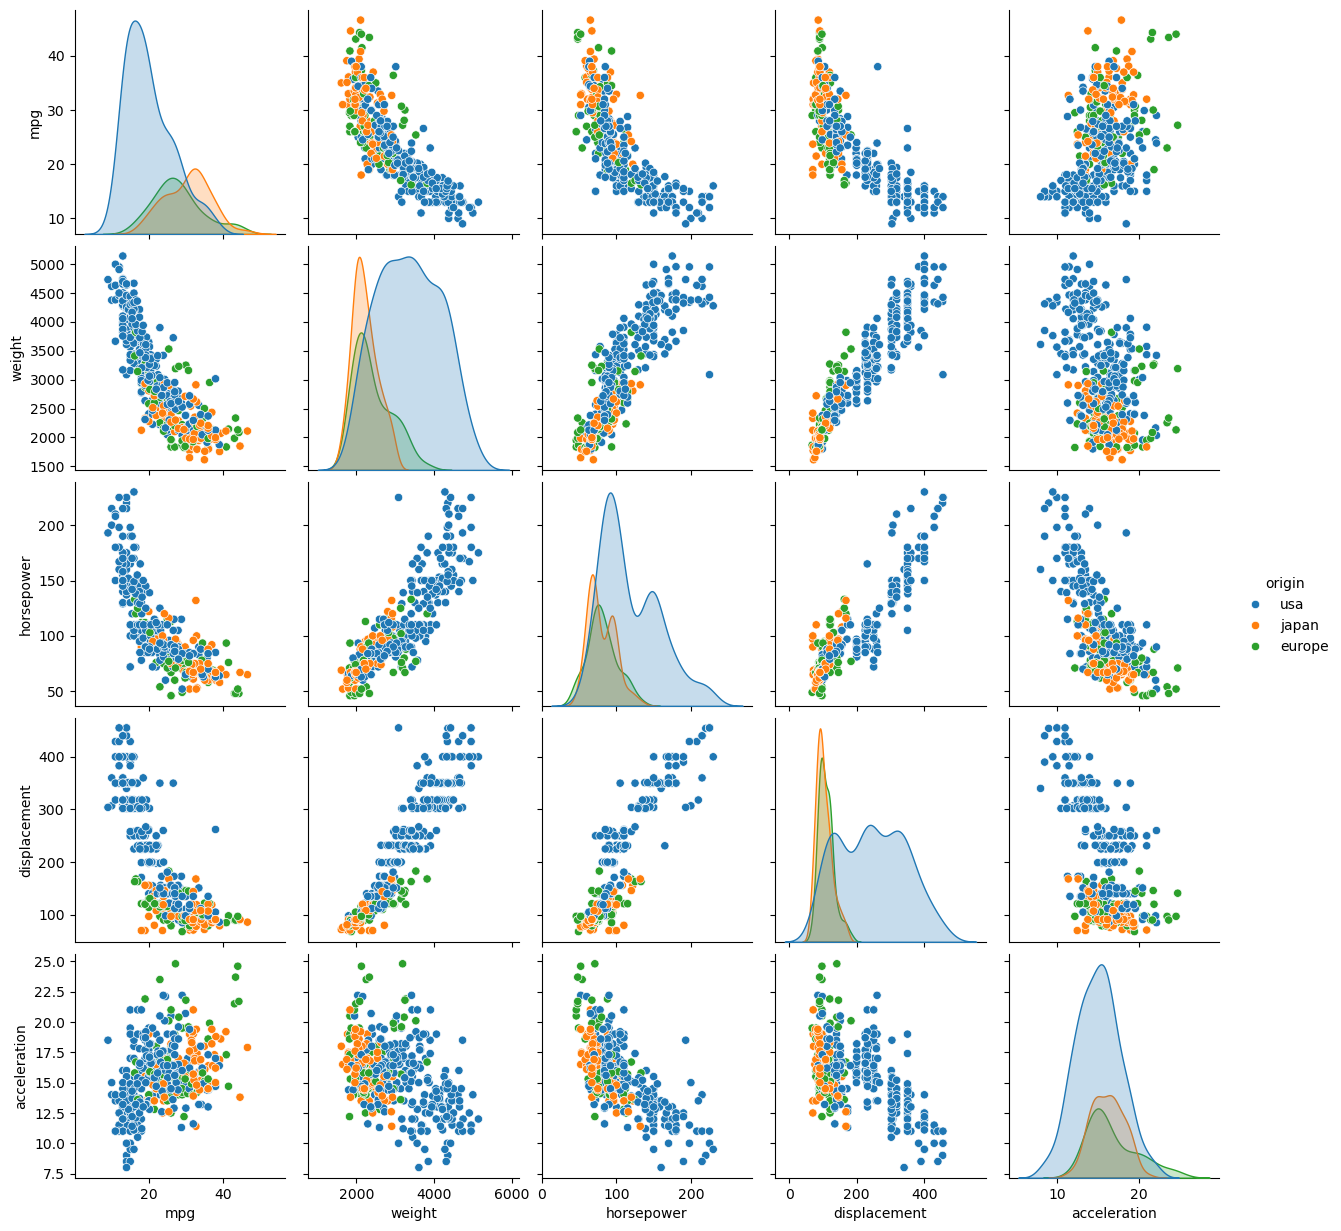

In [19]:
sns.pairplot(df_raw, vars=['mpg', 'weight', 'horsepower', 'displacement', 'acceleration'], hue='origin')
plt.show()